# PS1 — Noise-Robust Representation Learning: Autoencoder & Denoising Autoencoder
**Dataset:** Fashion-MNIST (one class = *normal*, all other classes = *anomalies*)  
**Models:** Convolutional Autoencoder (AE) and Denoising Autoencoder (DAE)  
**Research question:** How do latent dimensionality and input corruption affect reconstruction quality and the ability to separate normal from anomalous samples?

**Experiments:** latent ∈ {8, 16, 32} × train-noise ∈ {0 (standard AE), 0.1, 0.2 (DAE)} × test-noise ∈ {0, 0.1, 0.2}  
**Metrics:** MSE, MAE, PSNR, SSIM, AUROC, Precision, Recall, F1  
**Extension:** other noise distributions (Gaussian, salt & pepper, speckle, uniform, mixed) + adaptive thresholds.



## 1. Setup & configuration

In [1]:
import time, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt, seaborn as sns
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets
from sklearn.metrics import (precision_recall_fscore_support, roc_auc_score,
                             roc_curve, precision_recall_curve)

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

# ---------------- Configuration ----------------
NORMAL_CLASSES = [0]            # 0=T-shirt/top. Try [1] (Trouser), [7] (Sneaker), [9] (Ankle boot) ...
LATENT_DIMS    = [8, 16, 32]
NOISE_LEVELS   = [0.0, 0.1, 0.2]  # 0%,10%,20% -> noise std (on pixels scaled to [0,1]) / corruption fraction
EPOCHS, BATCH, LR = 15, 128, 1e-3
N_ANOMALY_TEST = 1000           # anomalies sampled for the test set (balanced vs. normal)
THR_PERCENTILE = 95             # threshold = 95th percentile of validation (normal) errors
CLASS_NAMES = ['T-shirt','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']

Device: cuda


## 2. Data: normal-only training, mixed normal/anomaly testing

In [2]:
tr = datasets.FashionMNIST('./data', train=True,  download=True)
te = datasets.FashionMNIST('./data', train=False, download=True)
Xtr_all = tr.data.float().div(255).unsqueeze(1); ytr_all = tr.targets.numpy()
Xte_all = te.data.float().div(255).unsqueeze(1); yte_all = te.targets.numpy()

rng = np.random.RandomState(SEED)
# --- train/val: normal samples only (unsupervised anomaly detection) ---
idx = np.where(np.isin(ytr_all, NORMAL_CLASSES))[0]; rng.shuffle(idx)
n_val = int(0.1*len(idx))
Xval, Xtrain = Xtr_all[idx[:n_val]], Xtr_all[idx[n_val:]]

# --- test: all normal + random anomalies ---
nidx = np.where(np.isin(yte_all, NORMAL_CLASSES))[0]
aidx = rng.choice(np.where(~np.isin(yte_all, NORMAL_CLASSES))[0], N_ANOMALY_TEST, replace=False)
tidx = np.concatenate([nidx, aidx])
Xte = Xte_all[tidx]; yte_cls = yte_all[tidx]
yte = (~np.isin(yte_cls, NORMAL_CLASSES)).astype(int)    # 1 = anomaly
print(f'Train {len(Xtrain)} | Val {len(Xval)} | Test {len(Xte)} (normal={int((yte==0).sum())}, anomaly={int(yte.sum())})')
print('Normal class(es):', [CLASS_NAMES[c] for c in NORMAL_CLASSES])

100%|██████████| 26.4M/26.4M [00:00<00:00, 115MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 3.72MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 57.3MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 12.6MB/s]


Train 5400 | Val 600 | Test 2000 (normal=1000, anomaly=1000)
Normal class(es): ['T-shirt']


## 3. Noise models, model, and metrics

In [3]:
def add_noise(x, kind='gaussian', level=0.1, g=None):
    """Corrupt images in [0,1]. `level` = std (gaussian/speckle/uniform) or pixel fraction (salt&pepper)."""
    if level <= 0: return x
    if kind == 'mixed':   # random distribution per call (used for a distribution-robust DAE)
        kind = ['gaussian','salt_pepper','speckle','uniform'][int(torch.randint(0,4,(1,)))]
    r = lambda: torch.randn(x.shape, generator=g, device=x.device)
    u = lambda: torch.rand(x.shape, generator=g, device=x.device)
    if kind == 'gaussian':      y = x + level*r()
    elif kind == 'speckle':     y = x + x*level*r()
    elif kind == 'uniform':     y = x + (u()*2-1)*level*np.sqrt(3)     # same std as gaussian(level)
    elif kind == 'salt_pepper':
        m = u(); y = x.clone(); y[m < level/2] = 0.; y[(m >= level/2) & (m < level)] = 1.
    else: raise ValueError(kind)
    return y.clamp(0,1)

class ConvAE(nn.Module):
    def __init__(self, latent):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(1,16,3,2,1), nn.ReLU(),
                                 nn.Conv2d(16,32,3,2,1), nn.ReLU(),
                                 nn.Flatten(), nn.Linear(32*7*7, latent))
        self.fc  = nn.Sequential(nn.Linear(latent, 32*7*7), nn.ReLU())
        self.dec = nn.Sequential(nn.ConvTranspose2d(32,16,3,2,1,output_padding=1), nn.ReLU(),
                                 nn.ConvTranspose2d(16,1,3,2,1,output_padding=1), nn.Sigmoid())
    def forward(self, x):
        return self.dec(self.fc(self.enc(x)).view(-1,32,7,7))

n_params = lambda m: sum(p.numel() for p in m.parameters())

# ---- SSIM (gaussian window, per image) ----
def _gauss_win(size=11, sigma=1.5):
    c = torch.arange(size).float() - size//2
    g = torch.exp(-c**2/(2*sigma**2)); g /= g.sum()
    return (g[:,None]*g[None,:]).view(1,1,size,size)
_W = _gauss_win()
def ssim_batch(a, b):
    C1, C2 = 0.01**2, 0.03**2
    mu_a, mu_b = F.conv2d(a,_W), F.conv2d(b,_W)
    s_aa = F.conv2d(a*a,_W)-mu_a**2; s_bb = F.conv2d(b*b,_W)-mu_b**2; s_ab = F.conv2d(a*b,_W)-mu_a*mu_b
    s = ((2*mu_a*mu_b+C1)*(2*s_ab+C2))/((mu_a**2+mu_b**2+C1)*(s_aa+s_bb+C2))
    return s.flatten(1).mean(1)

## 4. Training (standard AE = clean→clean; DAE = noisy→clean)

In [4]:
def train_model(latent, train_noise=0.0, kind='gaussian', epochs=EPOCHS, verbose=False):
    torch.manual_seed(SEED)
    model = ConvAE(latent).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loader = DataLoader(TensorDataset(Xtrain), batch_size=BATCH, shuffle=True)
    t0 = time.time()
    for ep in range(epochs):
        model.train(); tot = 0
        for (x,) in loader:
            x = x.to(device)
            xin = add_noise(x, kind, train_noise)          # fresh noise every batch
            loss = F.mse_loss(model(xin), x)                # target is always the CLEAN image
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item()*len(x)
        if verbose: print(f'  ep {ep+1:02d} loss {tot/len(Xtrain):.5f}')
    model.eval(); model.train_time = time.time()-t0
    return model

@torch.no_grad()
def reconstruct(model, X, kind='gaussian', level=0.0, seed=0):
    model.eval(); g = torch.Generator(device='cpu').manual_seed(seed)
    xin = add_noise(X, kind, level, g)
    out = torch.cat([model(xin[i:i+1024].to(device)).cpu() for i in range(0, len(X), 1024)])
    return xin, out

def anomaly_scores(rec, xin):                 # only the (possibly noisy) input is available at test time
    return ((rec-xin)**2).flatten(1).mean(1).numpy()

def val_scores(model, kind='gaussian', level=0.0, seed=1):
    xin, rec = reconstruct(model, Xval, kind, level, seed); return anomaly_scores(rec, xin)

def prf(scores, y, thr):
    p, r, f, _ = precision_recall_fscore_support(y, (scores > thr).astype(int), average='binary', zero_division=0)
    return p, r, f

def evaluate(model, kind='gaussian', level=0.0, seed=0):
    xin, rec = reconstruct(model, Xte, kind, level, seed)
    err = anomaly_scores(rec, xin)
    nm = torch.from_numpy(yte == 0)
    c, r = Xte[nm], rec[nm]                                    # reconstruction quality on NORMAL test samples vs CLEAN target
    se = ((r-c)**2).flatten(1).mean(1)
    res = dict(MSE=se.mean().item(), MAE=(r-c).abs().mean().item(),
               PSNR=(10*torch.log10(1/se.clamp_min(1e-10))).mean().item(),
               SSIM=ssim_batch(r, c).mean().item(), AUROC=roc_auc_score(yte, err))
    return res, err, xin

## 5. Main grid: latent dimension × training noise × test noise

In [5]:
models, rows = {}, []
for latent in LATENT_DIMS:
    for tn in NOISE_LEVELS:                      # tn = 0 -> standard AE, tn > 0 -> DAE
        print(f'Training latent={latent:>2} train_noise={tn}')
        m = train_model(latent, tn); models[(latent, tn)] = m
        thr = np.percentile(val_scores(m, 'gaussian', 0.0), THR_PERCENTILE)   # fixed threshold from clean normal val data
        for sn in NOISE_LEVELS:
            res, err, _ = evaluate(m, 'gaussian', sn)
            p, r, f = prf(err, yte, thr)
            rows.append(dict(model='AE' if tn==0 else 'DAE', latent=latent, train_noise=tn, test_noise=sn,
                             **res, Precision=p, Recall=r, F1=f, Params=n_params(m), TrainTime_s=m.train_time))
df = pd.DataFrame(rows)
df.round(4)

Training latent= 8 train_noise=0.0
Training latent= 8 train_noise=0.1
Training latent= 8 train_noise=0.2
Training latent=16 train_noise=0.0
Training latent=16 train_noise=0.1
Training latent=16 train_noise=0.2
Training latent=32 train_noise=0.0
Training latent=32 train_noise=0.1
Training latent=32 train_noise=0.2


,model,latent,train_noise,test_noise,MSE,MAE,PSNR,SSIM,AUROC,Precision,Recall,F1,Params,TrainTime_s
0,AE,8,0.0,0.0,0.0162,0.0714,18.7801,0.5658,0.8986,0.9079,0.562,0.6943,36233,5.2364
1,AE,8,0.0,0.1,0.0170,0.0762,18.5001,0.5509,0.8911,0.8908,0.620,0.7311,36233,5.2364
2,AE,8,0.0,0.2,0.0196,0.0879,17.7082,0.5132,0.8688,0.6771,0.929,0.7833,36233,5.2364
3,DAE,8,0.1,0.0,0.0164,0.0708,18.7072,0.5752,0.8959,0.8995,0.546,0.6795,36233,2.7693
4,DAE,8,0.1,0.1,0.0162,0.0717,18.7568,0.5719,0.8897,0.8843,0.604,0.7178,36233,2.7693
5,DAE,8,0.1,0.2,0.0175,0.0780,18.3263,0.5522,0.8701,0.6910,0.926,0.7915,36233,2.7693
6,DAE,8,0.2,0.0,0.0174,0.0727,18.3786,0.5624,0.8936,0.9003,0.542,0.6767,36233,2.3902
7,DAE,8,0.2,0.1,0.0170,0.0722,18.5342,0.5648,0.8888,0.8960,0.586,0.7086,36233,2.3902
8,DAE,8,0.2,0.2,0.0169,0.0737,18.5489,0.5598,0.8728,0.7256,0.883,0.7966,36233,2.3902
9,AE,16,0.0,0.0,0.0131,0.0632,19.7342,0.6131,0.9033,0.9079,0.572,0.7018,61329,2.1386


In [6]:
df.to_csv('results_main.csv', index=False)
df.round(4).sort_values('F1', ascending=False).head(10)

,model,latent,train_noise,test_noise,MSE,MAE,PSNR,SSIM,AUROC,Precision,Recall,F1,Params,TrainTime_s
8,DAE,8,0.2,0.2,0.0169,0.0737,18.5489,0.5598,0.8728,0.7256,0.883,0.7966,36233,2.3902
5,DAE,8,0.1,0.2,0.0175,0.0780,18.3263,0.5522,0.8701,0.6910,0.926,0.7915,36233,2.7693
2,AE,8,0.0,0.2,0.0196,0.0879,17.7082,0.5132,0.8688,0.6771,0.929,0.7833,36233,5.2364
10,AE,16,0.0,0.1,0.0138,0.0666,19.3963,0.6006,0.8929,0.8852,0.663,0.7581,61329,2.1386
13,DAE,16,0.1,0.1,0.0136,0.0647,19.5297,0.6059,0.8950,0.8896,0.653,0.7532,61329,2.1354
17,DAE,16,0.2,0.2,0.0145,0.0678,19.1897,0.5945,0.8702,0.6092,0.965,0.7469,61329,2.3481
16,DAE,16,0.2,0.1,0.0142,0.0658,19.3213,0.6030,0.8943,0.8887,0.639,0.7435,61329,2.3481
22,DAE,32,0.1,0.1,0.0122,0.0603,19.9840,0.6300,0.8911,0.8873,0.630,0.7368,111521,2.5143
25,DAE,32,0.2,0.1,0.0130,0.0626,19.5850,0.6280,0.8922,0.8895,0.628,0.7362,111521,2.0788
1,AE,8,0.0,0.1,0.0170,0.0762,18.5001,0.5509,0.8911,0.8908,0.620,0.7311,36233,5.2364


## 6. Analysis plots

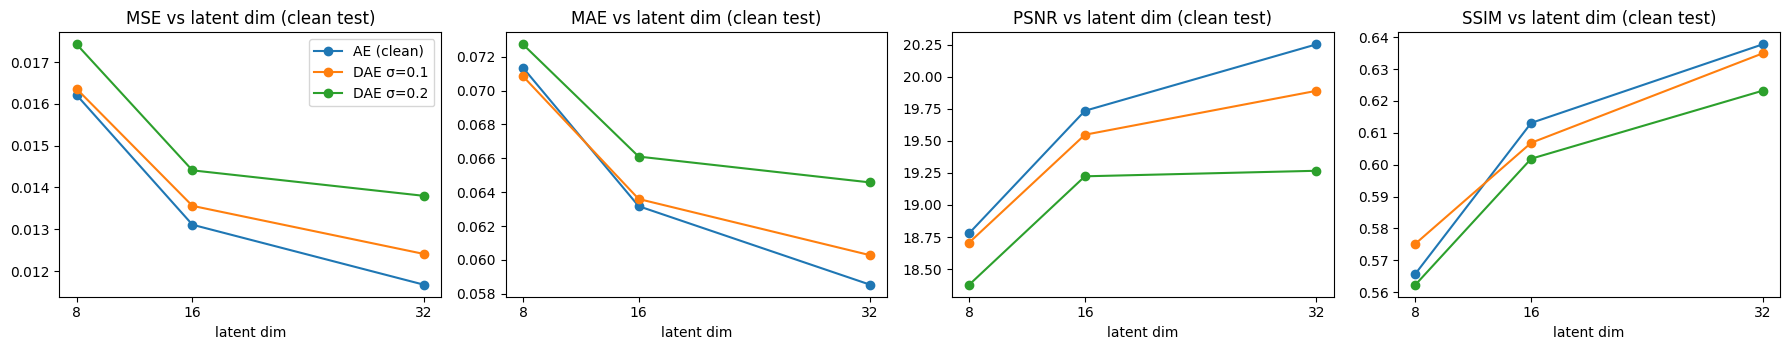

In [7]:
# (a) Latent dimension vs reconstruction quality (clean test input)
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
for a, met in zip(ax, ['MSE','MAE','PSNR','SSIM']):
    for tn in NOISE_LEVELS:
        d = df[(df.train_noise==tn)&(df.test_noise==0.0)]
        a.plot(d.latent, d[met], 'o-', label='AE (clean)' if tn==0 else f'DAE σ={tn}')
    a.set_title(f'{met} vs latent dim (clean test)'); a.set_xlabel('latent dim'); a.set_xticks(LATENT_DIMS)
ax[0].legend(); plt.tight_layout(); plt.show()

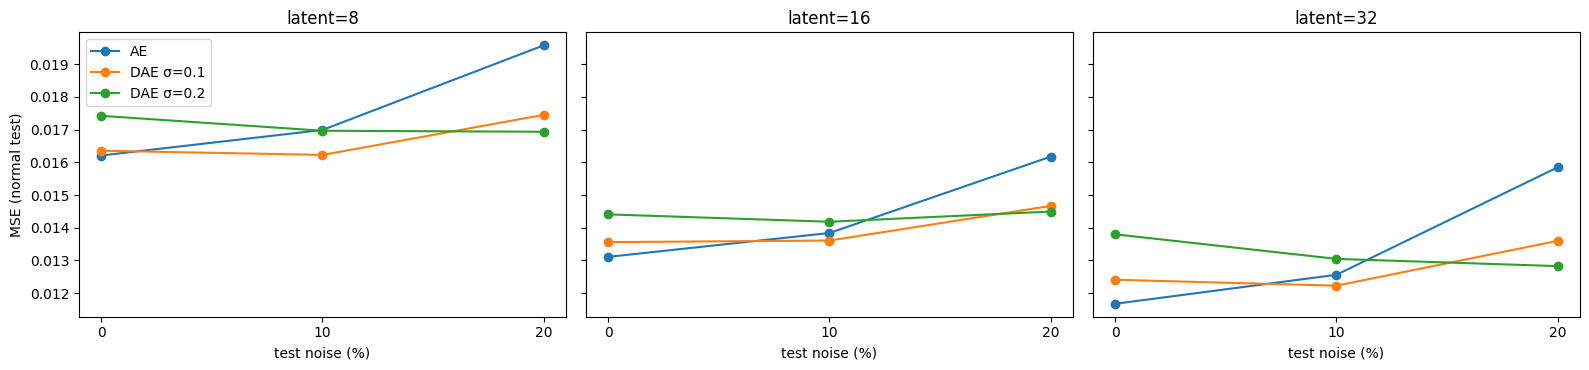

In [8]:
# (b) Robustness: reconstruction quality (MSE vs CLEAN target) as test noise grows
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for a, latent in zip(ax, LATENT_DIMS):
    for tn in NOISE_LEVELS:
        d = df[(df.latent==latent)&(df.train_noise==tn)]
        a.plot(d.test_noise*100, d.MSE, 'o-', label='AE' if tn==0 else f'DAE σ={tn}')
    a.set_title(f'latent={latent}'); a.set_xlabel('test noise (%)'); a.set_xticks([0,10,20])
ax[0].set_ylabel('MSE (normal test)'); ax[0].legend(); plt.tight_layout(); plt.show()

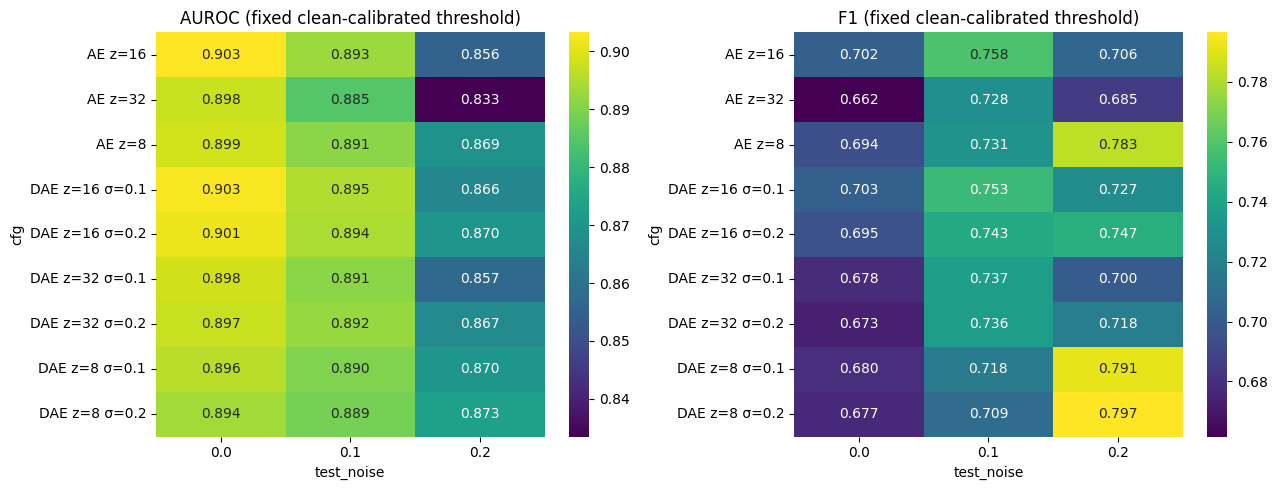

In [9]:
# (c) Anomaly detection heatmaps: AUROC and F1  (rows = latent/model, cols = test noise)
df['cfg'] = df.apply(lambda r: f"{r.model} z={int(r.latent)}" + (f" σ={r.train_noise}" if r.train_noise>0 else ''), axis=1)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, met in zip(ax, ['AUROC','F1']):
    pv = df.pivot(index='cfg', columns='test_noise', values=met)
    sns.heatmap(pv, annot=True, fmt='.3f', cmap='viridis', ax=a); a.set_title(met+' (fixed clean-calibrated threshold)')
plt.tight_layout(); plt.show()

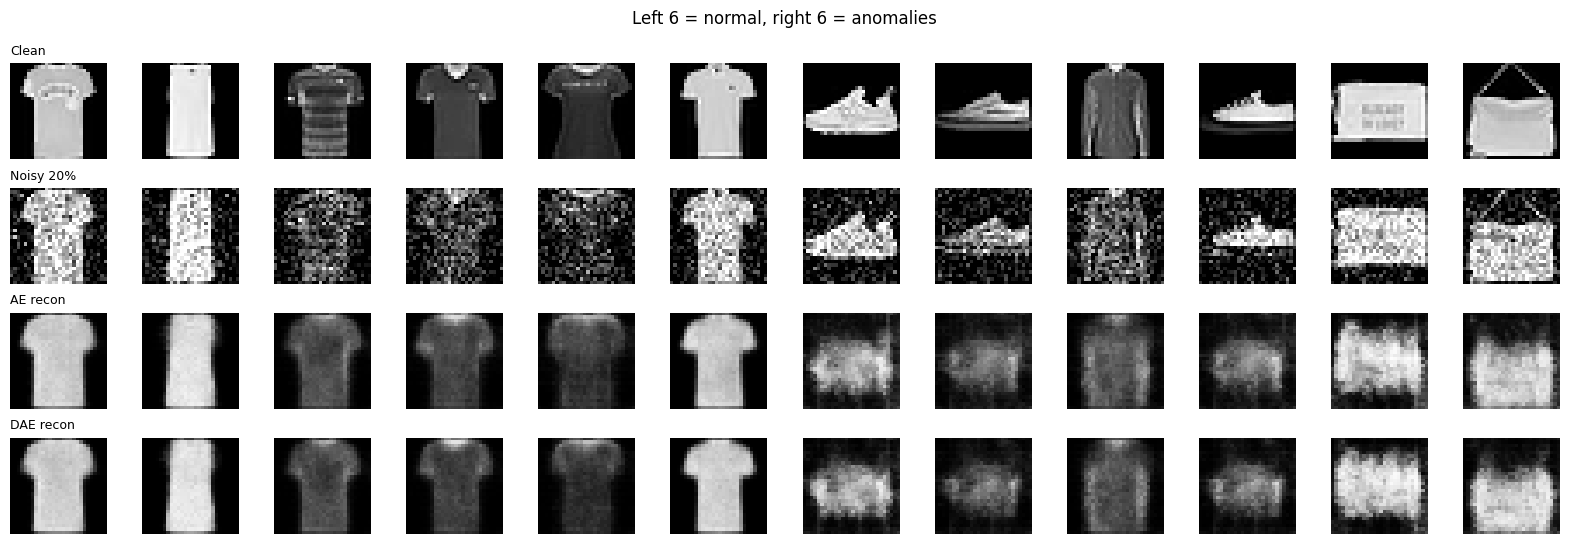

In [10]:
# (d) Qualitative reconstructions (latent=16): normal row vs anomaly row, noisy input @20%
m_ae, m_dae = models[(16,0.0)], models[(16,0.2)]
ni = np.where(yte==0)[0][:6]; ai = np.where(yte==1)[0][:6]
sel = np.concatenate([ni, ai]); X = Xte[sel]
xin, r_ae = reconstruct(m_ae, X, 'gaussian', 0.2); _, r_dae = reconstruct(m_dae, X, 'gaussian', 0.2)
rowsimg = [('Clean', X), ('Noisy 20%', xin), ('AE recon', r_ae), ('DAE recon', r_dae)]
fig, ax = plt.subplots(4, 12, figsize=(16, 5.5))
for i, (name, imgs) in enumerate(rowsimg):
    for j in range(12):
        ax[i,j].imshow(imgs[j,0], cmap='gray', vmin=0, vmax=1); ax[i,j].axis('off')
    ax[i,0].set_title(name, loc='left', fontsize=9)
fig.suptitle('Left 6 = normal, right 6 = anomalies'); plt.tight_layout(); plt.show()

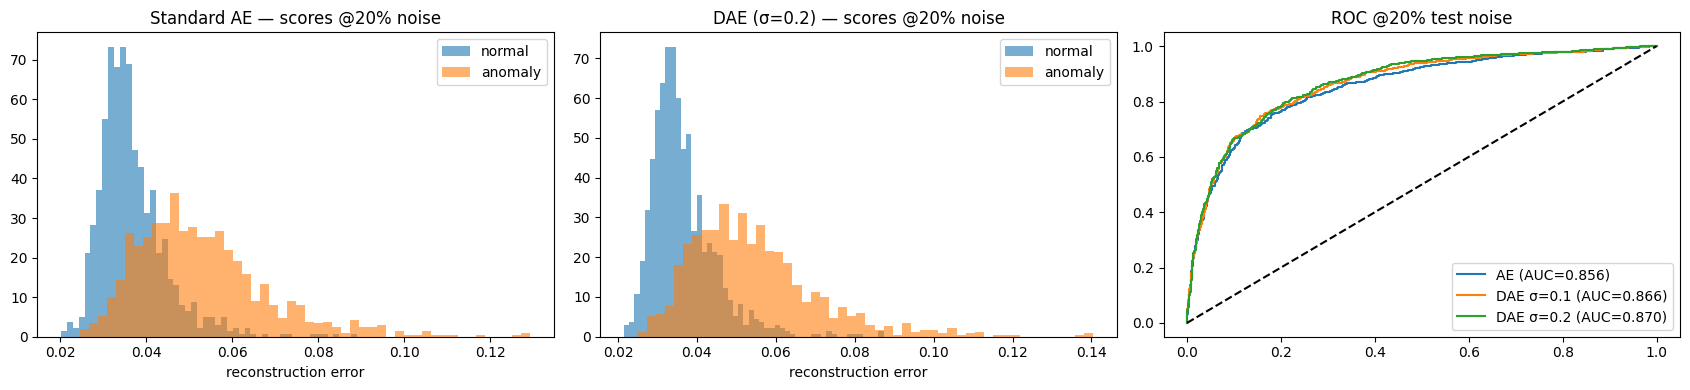

In [11]:
# (e) Error distributions + ROC for the latent=16 models at 20% test noise
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, (tn, title) in zip(ax[:2], [(0.0,'Standard AE'), (0.2,'DAE (σ=0.2)')]):
    _, err, _ = evaluate(models[(16,tn)], 'gaussian', 0.2)
    a.hist(err[yte==0], bins=50, alpha=.6, label='normal', density=True)
    a.hist(err[yte==1], bins=50, alpha=.6, label='anomaly', density=True)
    a.set_title(f'{title} — scores @20% noise'); a.set_xlabel('reconstruction error'); a.legend()
for tn in NOISE_LEVELS:
    _, err, _ = evaluate(models[(16,tn)], 'gaussian', 0.2); fpr, tpr, _ = roc_curve(yte, err)
    ax[2].plot(fpr, tpr, label=f"{'AE' if tn==0 else 'DAE σ='+str(tn)} (AUC={roc_auc_score(yte,err):.3f})")
ax[2].plot([0,1],[0,1],'k--'); ax[2].set_title('ROC @20% test noise'); ax[2].legend(); plt.tight_layout(); plt.show()

## 7. Model complexity vs performance
Parameters, training time and inference latency for each latent size, against detection performance on clean data.

,latent,Params,TrainTime_s,Infer_ms_per_sample,MSE,SSIM,AUROC,F1
0,8,36233,5.2,0.0029,0.0162,0.5658,0.8986,0.6943
1,16,61329,2.1,0.0031,0.0131,0.6131,0.9033,0.7018
2,32,111521,2.4,0.0031,0.0117,0.6377,0.8976,0.6616


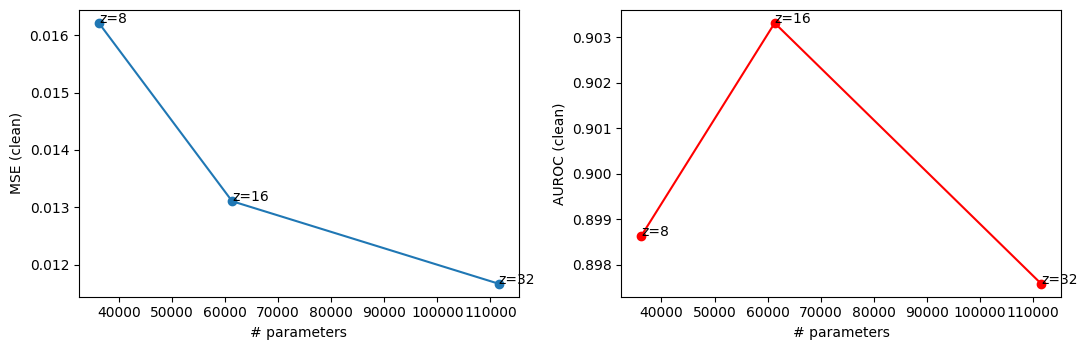

In [12]:
cx = []
for (latent, tn), m in models.items():
    if tn != 0.0: continue
    xb = Xte[:1000].to(device)
    with torch.no_grad():
        m(xb); t0 = time.time()
        for _ in range(5): m(xb)
        if device.type=='cuda': torch.cuda.synchronize()
        lat_ms = (time.time()-t0)/5/1000*1000
    d = df[(df.latent==latent)&(df.train_noise==0.0)&(df.test_noise==0.0)].iloc[0]
    cx.append(dict(latent=latent, Params=n_params(m), TrainTime_s=round(m.train_time,1),
                   Infer_ms_per_sample=round(lat_ms,4), MSE=d.MSE, SSIM=d.SSIM, AUROC=d.AUROC, F1=d.F1))
cx = pd.DataFrame(cx); display(cx.round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(cx.Params, cx.MSE, 'o-'); ax[0].set_xlabel('# parameters'); ax[0].set_ylabel('MSE (clean)')
ax[1].plot(cx.Params, cx.AUROC, 'o-r'); ax[1].set_xlabel('# parameters'); ax[1].set_ylabel('AUROC (clean)')
for a in ax:
    for _, r in cx.iterrows(): a.annotate(f"z={int(r.latent)}", (r.Params, a.lines[0].get_ydata()[list(cx.Params).index(r.Params)]))
plt.tight_layout(); plt.show()

## 8. Extension A — Robustness under different noise distributions
Test (latent = 16) at noise level 0.2 under **Gaussian, salt & pepper, speckle, uniform**.  
We compare: standard AE, DAE trained on Gaussian noise, and a **mixed-noise DAE** trained on a random distribution per batch.

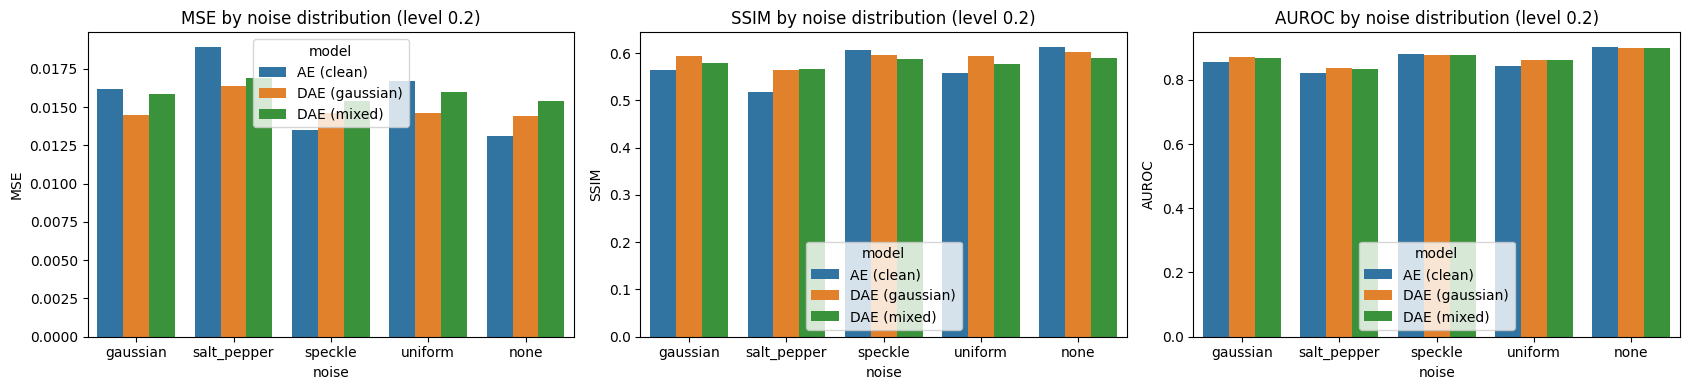

noise,gaussian,none,salt_pepper,speckle,uniform
model,,,,,
AE (clean),0.856,0.903,0.821,0.880,0.844
DAE (gaussian),0.870,0.901,0.836,0.877,0.863
DAE (mixed),0.870,0.901,0.834,0.878,0.863


In [13]:
LAT = 16; KINDS = ['gaussian','salt_pepper','speckle','uniform']; LVL = 0.2
ext_models = {'AE (clean)': models[(LAT,0.0)],
              'DAE (gaussian)': models[(LAT,0.2)],
              'DAE (mixed)': train_model(LAT, 0.2, kind='mixed')}
rows = []
for name, m in ext_models.items():
    for k in KINDS + ['none']:
        res, err, _ = evaluate(m, k, 0.0 if k=='none' else LVL)
        rows.append(dict(model=name, noise=k, **res))
dn = pd.DataFrame(rows); dn.to_csv('results_noise_types.csv', index=False)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, met in zip(ax, ['MSE','SSIM','AUROC']):
    sns.barplot(data=dn, x='noise', y=met, hue='model', ax=a); a.set_title(f'{met} by noise distribution (level {LVL})')
plt.tight_layout(); plt.show()
dn.pivot(index='model', columns='noise', values='AUROC').round(3)

## 9. Extension B — Adaptive reconstruction thresholds
Under input noise, the reconstruction error of *normal* samples rises, so a threshold calibrated on clean data produces many false alarms.
Strategies compared (all calibrated on **normal validation data only**):

| Strategy | Idea | Needs to know noise? |
|---|---|---|
| **Fixed** | 95th percentile of clean validation errors | no |
| **Noise-aware percentile** | 95th percentile of validation errors under the *same* noise (oracle) | yes |
| **Noise-aware MAD** | median + 3·1.4826·MAD of validation errors under same noise (robust) | yes |
| **Per-sample adaptive** | Estimate each input's noise σ̂ (Immerkaer Laplacian estimator), regress error on σ̂ using Gaussian-noise validation data, threshold = prediction + 95th pct residual | **no** (estimated) |
| *Oracle best-F1* | upper bound using test labels (reference only) | – |

strategy                    Fixed  Noise-aware MAD  Noise-aware pct  \
model          noise                                                  
AE (clean)     gaussian     0.706            0.586            0.612   
               salt_pepper  0.667            0.314            0.607   
               speckle      0.760            0.694            0.688   
               uniform      0.693            0.540            0.575   
DAE (gaussian) gaussian     0.747            0.586            0.637   
               salt_pepper  0.667            0.352            0.634   
               speckle      0.756            0.697            0.673   
               uniform      0.731            0.571            0.601   
DAE (mixed)    gaussian     0.761            0.602            0.639   
               salt_pepper  0.667            0.366            0.636   
               speckle      0.754            0.690            0.674   
               uniform      0.745            0.571            0.627   

strategy                    Oracle best-F1  Per-sample adaptive  
model          noise                                             
AE (clean)     gaussian              0.787                0.625  
               salt_pepper           0.751                0.670  
               speckle               0.814                0.746  
               uniform               0.775                0.599  
DAE (gaussian) gaussian              0.802                0.639  
               salt_pepper           0.766                0.670  
               speckle               0.812                0.746  
               uniform               0.799                0.625  
DAE (mixed)    gaussian              0.797                0.638  
               salt_pepper           0.767                0.671  
               speckle               0.816                0.749  
               uniform               0.799                0.623

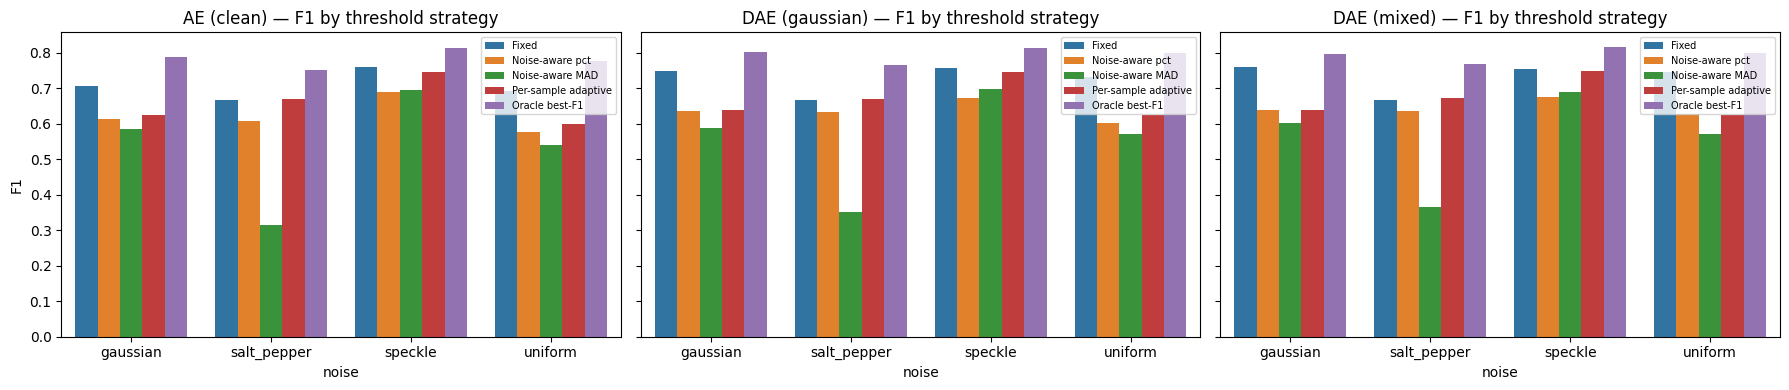

In [14]:
def immerkaer(x):          # fast noise-std estimate per image (Immerkaer 1996)
    k = torch.tensor([[1,-2,1],[-2,4,-2],[1,-2,1]], dtype=torch.float32).view(1,1,3,3)
    return (np.sqrt(np.pi/2)/(6*26*26)) * F.conv2d(x, k).abs().flatten(1).sum(1).numpy()

_cache = {}
def fit_adaptive(model, q=THR_PERCENTILE):
    if id(model) in _cache: return _cache[id(model)]
    S, E = [], []
    for lvl in [0, .05, .1, .15, .2, .25]:                   # calibrate on Gaussian noise only
        xin, rec = reconstruct(model, Xval, 'gaussian', lvl, seed=2)
        S.append(immerkaer(xin)); E.append(anomaly_scores(rec, xin))
    S, E = np.concatenate(S), np.concatenate(E)
    b, a = np.polyfit(S, E, 1); _cache[id(model)] = (a, b, np.percentile(E-(a+b*S), q))
    return _cache[id(model)]

def threshold_report(model, kind, level):
    res, err, xin = evaluate(model, kind, level)
    out = {}
    thr_fixed = np.percentile(val_scores(model,'gaussian',0.0), THR_PERCENTILE)
    vs = val_scores(model, kind, level)
    med = np.median(vs); mad = 1.4826*np.median(np.abs(vs-med))
    a, b, q = fit_adaptive(model)
    thr_i = a + b*immerkaer(xin) + q
    for name, thr in [('Fixed', thr_fixed), ('Noise-aware pct', np.percentile(vs, THR_PERCENTILE)),
                      ('Noise-aware MAD', med+3*mad), ('Per-sample adaptive', thr_i)]:
        p, r, f = prf(err, yte, thr); out[name] = dict(Precision=p, Recall=r, F1=f)
    P, R, T = precision_recall_curve(yte, err); out['Oracle best-F1'] = dict(Precision=np.nan, Recall=np.nan, F1=np.max(2*P*R/(P+R+1e-12)))
    return out

rows = []
for mname in ['AE (clean)', 'DAE (gaussian)', 'DAE (mixed)']:
    for kind in KINDS:
        for strat, v in threshold_report(ext_models[mname], kind, LVL).items():
            rows.append(dict(model=mname, noise=kind, strategy=strat, **v))
dt = pd.DataFrame(rows); dt.to_csv('results_thresholds.csv', index=False)
display(dt.pivot_table(index=['model','noise'], columns='strategy', values='F1').round(3))
fig, ax = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for a, mname in zip(ax, ext_models):
    sns.barplot(data=dt[dt.model==mname], x='noise', y='F1', hue='strategy', ax=a); a.set_title(mname + ' — F1 by threshold strategy')
    a.legend(fontsize=7)
plt.tight_layout(); plt.show()

In [15]:
# Precision / Recall trade-off for the Gaussian case (level 0.2), DAE
display(dt[(dt.model=='DAE (gaussian)')&(dt.noise=='gaussian')].set_index('strategy')[['Precision','Recall','F1']].round(3))

,Precision,Recall,F1
strategy,,,
Fixed,0.609,0.965,0.747
Noise-aware pct,0.909,0.490,0.637
Noise-aware MAD,0.921,0.430,0.586
Per-sample adaptive,0.935,0.486,0.639
Oracle best-F1,NaN,NaN,0.802
